In [ ]:
#importing headerfiles
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
#import dataset
df = pd.read_csv('titanic.csv')
df1 = pd.read_csv('titanic.csv')

In [ ]:
#eda preprosessing
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
df.shape
#output columns and rows

(891, 12)

In [ ]:
df.isnull()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,False,False,False,False,False,False,False,False,False,False,True,False
1,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,True,False
3,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
886,False,False,False,False,False,False,False,False,False,False,True,False
887,False,False,False,False,False,False,False,False,False,False,False,False
888,False,False,False,False,False,True,False,False,False,False,True,False
889,False,False,False,False,False,False,False,False,False,False,False,False


In [ ]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [ ]:
df[df.duplicated()]
df.drop_duplicates(inplace = True)
df.reset_index(drop = True , inplace = True)

In [ ]:
df['Age']  = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(str(df['Embarked'].mode()))

df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [ ]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

<Axes: >

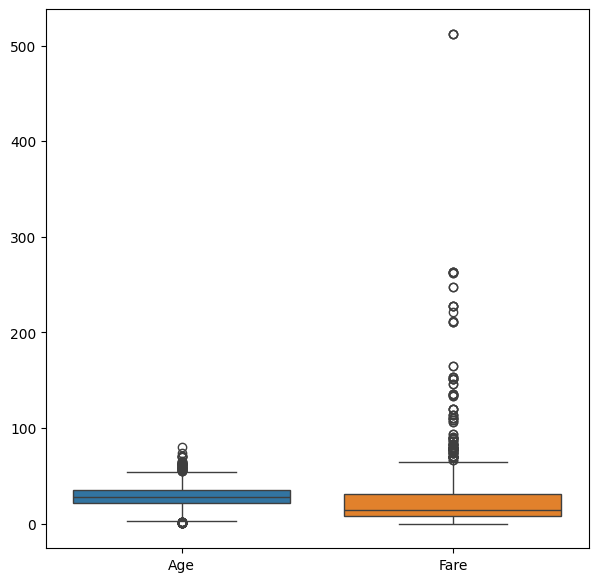

In [ ]:
#to detecct outlyers
plt.figure(figsize=(7,7))
sns.boxplot(data = df[["Age","Fare"]])

In [ ]:
def detect_outliers(data):
    outliers = []
    data = sorted(data)
    q1 = np.percentile(data,25)
    q3 = np.percentile(data,75)
    IQR = q3-q1
    lwr_bound = q1 - (1.5*IQR)
    upr_bound = q3 + (1.5*IQR)
    for i in data:
        if (i<lwr_bound or i>upr_bound):
            outliers.append(i)
    return outliers


for i in ['Age','Fare']:
    outliers = detect_outliers(df[i])
    print('outliers in', i, ' attribute', outliers)


outliers in Age  attribute [0.42, 0.67, 0.75, 0.75, 0.83, 0.83, 0.92, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 55.0, 55.0, 55.5, 56.0, 56.0, 56.0, 56.0, 57.0, 57.0, 58.0, 58.0, 58.0, 58.0, 58.0, 59.0, 59.0, 60.0, 60.0, 60.0, 60.0, 61.0, 61.0, 61.0, 62.0, 62.0, 62.0, 62.0, 63.0, 63.0, 64.0, 64.0, 65.0, 65.0, 65.0, 66.0, 70.0, 70.0, 70.5, 71.0, 71.0, 74.0, 80.0]
outliers in Fare  attribute [66.6, 66.6, 69.3, 69.3, 69.55, 69.55, 69.55, 69.55, 69.55, 69.55, 69.55, 71.0, 71.0, 71.2833, 73.5, 73.5, 73.5, 73.5, 73.5, 75.25, 76.2917, 76.7292, 76.7292, 76.7292, 77.2875, 77.2875, 77.9583, 77.9583, 77.9583, 78.2667, 78.2667, 78.85, 78.85, 79.2, 79.2, 79.2, 79.2, 79.65, 79.65, 79.65, 80.0, 80.0, 81.8583, 82.1708, 82.1708, 83.1583, 83.1583, 83.1583, 83.475, 83.475, 86.5, 86.5, 86.5, 89.1042, 89.1042, 90.0, 90.0, 90.0, 90.0, 91.0792, 91.0792, 93.5, 93.5, 106.425, 106.425, 108.9, 108.9, 110.8833, 110.8833, 110.8833, 110.8833, 113.275, 113.275, 113.275, 120.

In [ ]:
df.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [ ]:

df.nunique()


,0
PassengerId,891
Survived,2
Pclass,3
Name,891
Sex,2
Age,88
SibSp,7
Parch,7
Ticket,681
Fare,248


In [ ]:
#data label encoding
df["Sex"] = df["Sex"].replace('male',0)
df["Sex"] = df["Sex"].replace('female',1)
df["embarked"] = df["Embarked"].replace('S',3)
df["embarked"] = df["embarked"].replace('C',1)
df["embarked"] = df["embarked"].replace('Q',2)
df.head(10)


/tmp/ipykernel_528/1629799140.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["Sex"] = df["Sex"].replace('female',1)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,embarked
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,NaN,S,3
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,PC 17599,71.2833,C85,C,1
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,3
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,113803,53.1000,C123,S,3
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,373450,8.0500,NaN,S,3
5,6,0,3,"Moran, Mr. James",0,28.0,0,0,330877,8.4583,NaN,Q,2
6,7,0,1,"McCarthy, Mr. Timothy J",0,54.0,0,0,17463,51.8625,E46,S,3
7,8,0,3,"Palsson, Master. Gosta Leonard",0,2.0,3,1,349909,21.0750,NaN,S,3
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",1,27.0,0,2,347742,11.1333,NaN,S,3
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",1,14.0,1,0,237736,30.0708,NaN,C,1


In [ ]:
#get survival count
df['Survived'].value_counts()

,count
Survived,
0,549
1,342


In [ ]:
# how many male and female survived
df[df['Survived']==1]['Sex'].value_counts()

,count
Sex,
1,233
0,109


In [ ]:
# how many male and female  not survived
df[df['Survived']==0]['Sex'].value_counts()

,count
Sex,
0,468
1,81


In [ ]:
df['Age'].value_counts()

,count
Age,
28.00,202
24.00,30
22.00,27
18.00,26
30.00,25
...,...
24.50,1
0.67,1
0.42,1


out of 891 62% people died


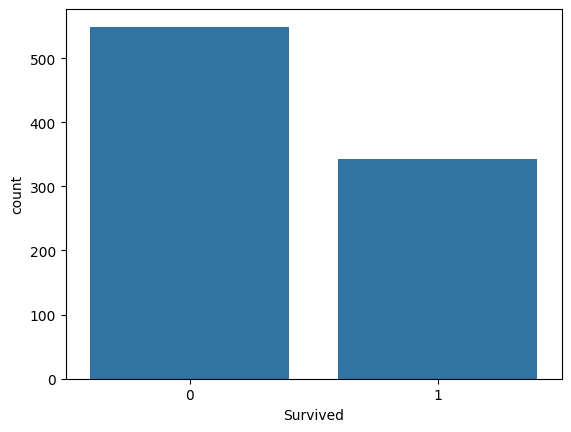

In [ ]:
# univarent (countplot and histplot)
sns.countplot(x= 'Survived', data = df)
plt.savefig('chart.png',dpi=300,bbox_inches='tight')
death = round (df['Survived'].value_counts().values[0]/891*100)
print('out of 891 {}% people died'.format(death))

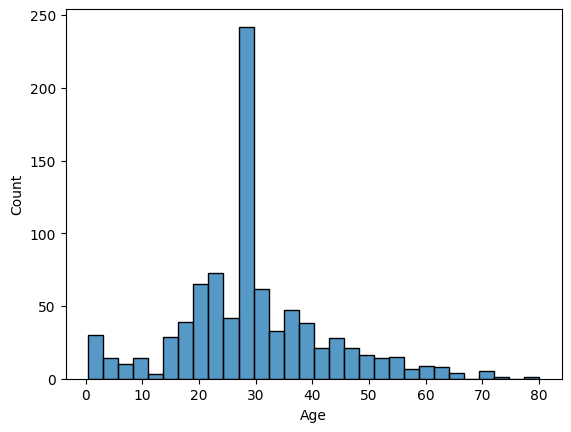

In [ ]:

sns.histplot(x= 'Age', data = df)
mean = round(df['Age'].mean())
plt.savefig('chart.png',dpi=300,bbox_inches='tight')


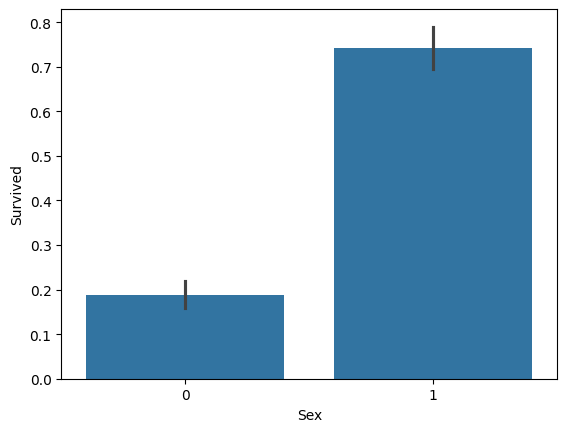

In [ ]:
#bivarent (bar  plot)
sns.barplot(x ='Sex' ,y= 'Survived', data = df)
plt.savefig('chart.png',dpi=300,bbox_inches='tight')

/tmp/ipykernel_528/3756849966.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x ='Age' ,y= 'Fare' ,data = df , palette ='viridis')


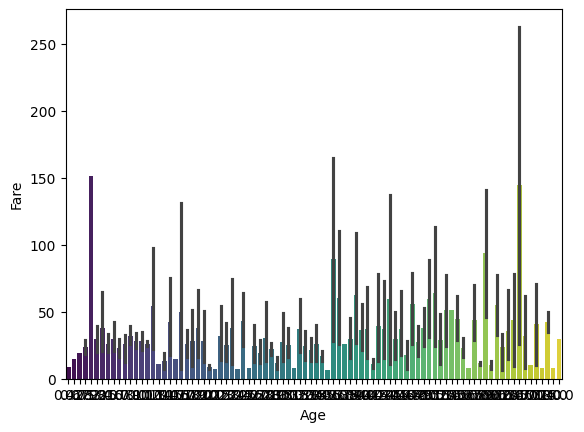

In [ ]:
sns.barplot(x ='Age' ,y= 'Fare' ,data = df , palette ='viridis')
plt.savefig('chart.png',dpi=300,bbox_inches='tight')

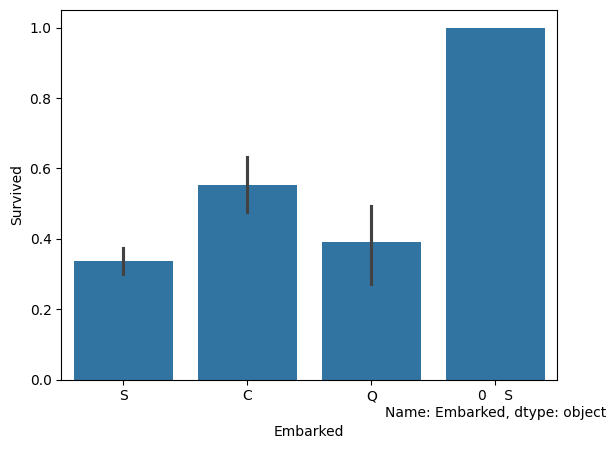

In [ ]:
sns.barplot(x ='Embarked' ,y= 'Survived', data = df)
plt.savefig('chart.png',dpi=300,bbox_inches='tight')

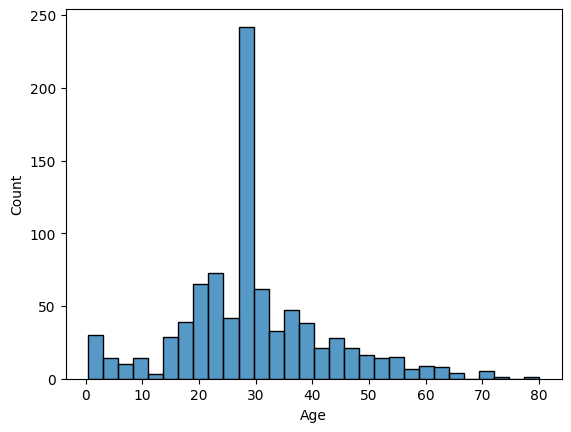

In [ ]:
sns.histplot(x ='Age', data = df)
plt.savefig('chart.png',dpi=300,bbox_inches='tight')

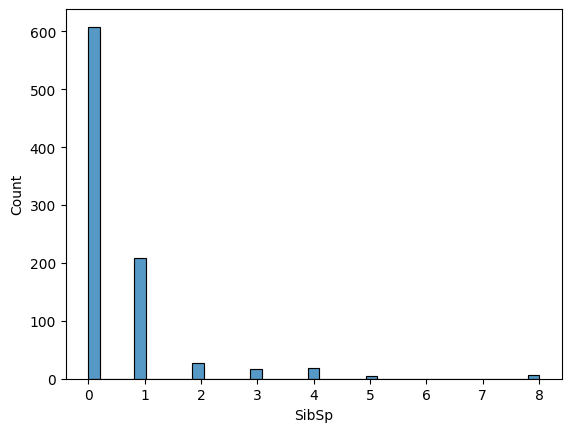

In [ ]:
sns.histplot(x ='SibSp', data = df)
plt.savefig('chart.png',dpi=300,bbox_inches='tight')

<Axes: xlabel='Age', ylabel='Fare'>

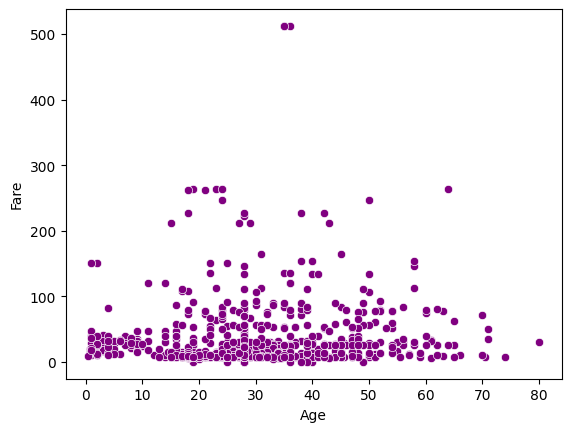

In [ ]:
sns.scatterplot(x= 'Age' , y= 'Fare', data = df, color='purple')

<Axes: xlabel='Sex', ylabel='Age'>

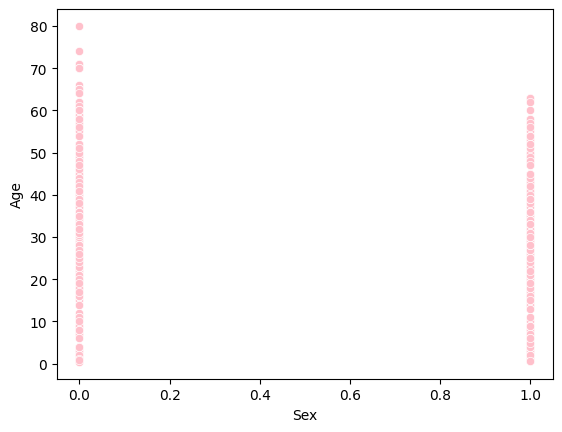

In [ ]:
sns.scatterplot(x= 'Sex' , y= 'Age', data = df, color='Pink')

<Axes: xlabel='Age', ylabel='Fare'>

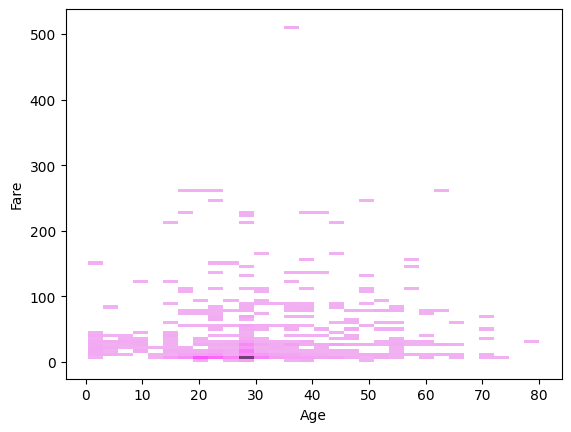

In [ ]:
sns.histplot(x= 'Age' , y= 'Fare', data = df, color='purple')

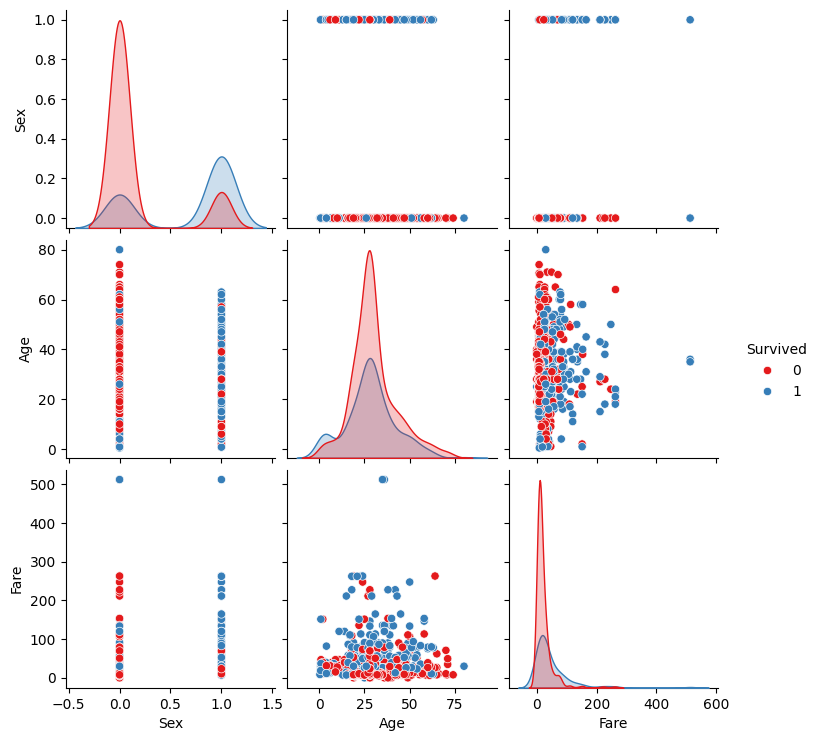

In [ ]:
sns.pairplot(df[[ 'Sex', 'Age', 'Fare', "Survived"]],hue = 'Survived', palette='Set1')
plt.savefig('chart.png',dpi=300,bbox_inches='tight')

In [ ]:
df.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,int64
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


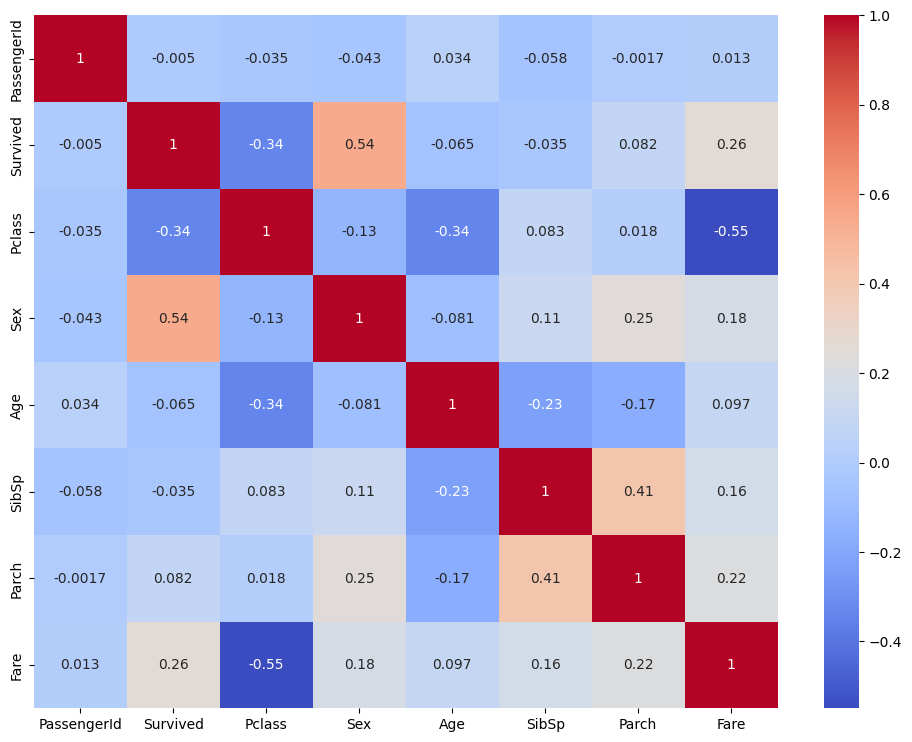

In [ ]:
plt.figure(figsize=(12,9))
sns.heatmap(df.select_dtypes(include=[int,float]).corr(), annot=True,cmap='coolwarm')
plt.savefig('chart.png',dpi=300,bbox_inches='tight')


In [ ]:
numeric_df = df.select_dtypes(include=[int,float])
corr_matrix = numeric_df.corr().fillna(0)
print(corr_matrix)


             PassengerId  Survived    Pclass       Sex       Age     SibSp  \
PassengerId     1.000000 -0.005007 -0.035144 -0.042939  0.034212 -0.057527   
Survived       -0.005007  1.000000 -0.338481  0.543351 -0.064910 -0.035322   
Pclass         -0.035144 -0.338481  1.000000 -0.131900 -0.339898  0.083081   
Sex            -0.042939  0.543351 -0.131900  1.000000 -0.081163  0.114631   
Age             0.034212 -0.064910 -0.339898 -0.081163  1.000000 -0.233296   
SibSp          -0.057527 -0.035322  0.083081  0.114631 -0.233296  1.000000   
Parch          -0.001652  0.081629  0.018443  0.245489 -0.172482  0.414838   
Fare            0.012658  0.257307 -0.549500  0.182333  0.096688  0.159651   

                Parch      Fare  
PassengerId -0.001652  0.012658  
Survived     0.081629  0.257307  
Pclass       0.018443 -0.549500  
Sex          0.245489  0.182333  
Age         -0.172482  0.096688  
SibSp        0.414838  0.159651  
Parch        1.000000  0.216225  
Fare         0.216225  1.

<Axes: >

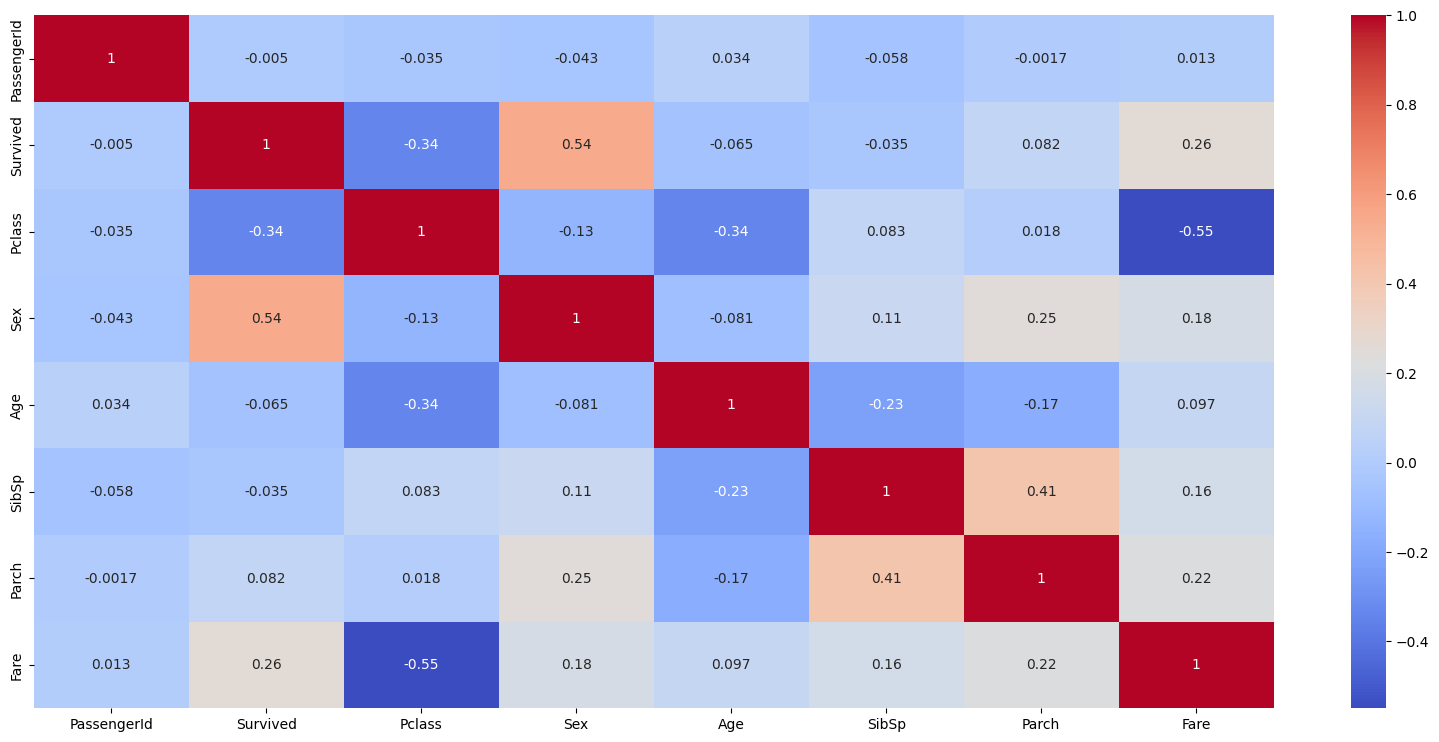

In [ ]:
plt.figure(figsize=(20,9))
sns.heatmap(corr_matrix, annot=True,cmap='coolwarm')


In [ ]:
numeric_df = df.select_dtypes(include=[int, float])
corr_matrix = numeric_df.corr()
corr_matrix["Survived"].sort_values(ascending=False)

,Survived
Survived,1.000000
Sex,0.543351
Fare,0.257307
Parch,0.081629
PassengerId,-0.005007
SibSp,-0.035322
Age,-0.064910
Pclass,-0.338481


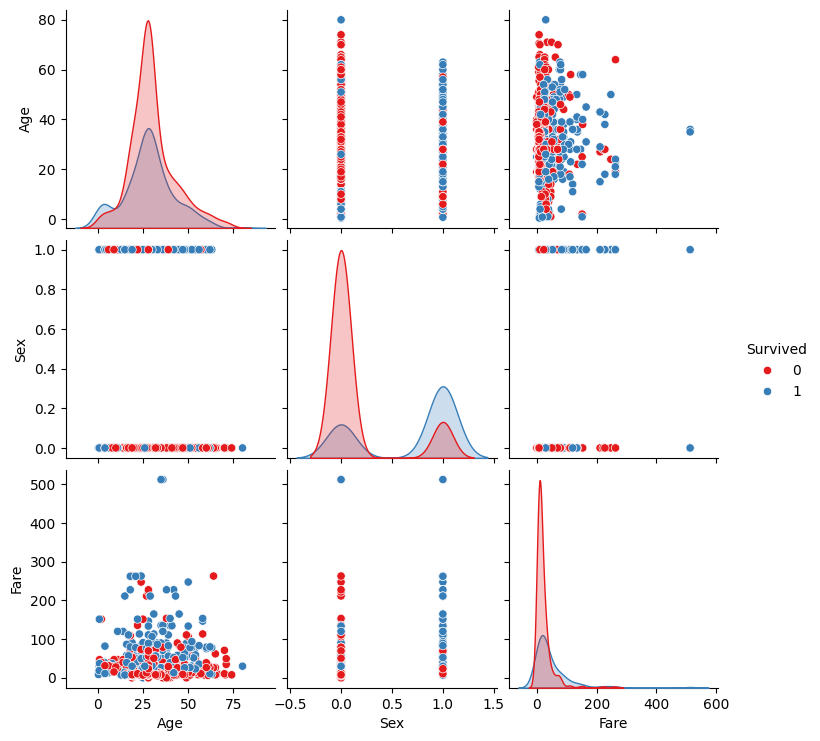

In [ ]:
sns.pairplot(df[["Age","Sex","Fare","Survived"]],hue="Survived", palette='Set1')


In [ ]:
from sklearn.model_selection import train_test_split
#SPLIT DATASET IN FEATURES AND TARGET
feature_cols = ['Sex', 'Age', 'Fare', 'Embarked']
X = df[feature_cols] #FEATURES
y = df.Survived #TARGET

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2) #SPLIT INTO TRANING (80) AND TESTING (20)

X_train.shape

(712, 4)

In [ ]:
X_test.shape

(179, 4)

In [ ]:
#LEARNINGS
#imputation - replacing the null values
#univariant   1 depended on it
# bivarent - 2 depended on it
# multivalue - depended on more than 1
#corelation - hitmap or scattermap
# outlayers - points outside prediction range
#eda - exploraratory data analysis - examines , summarize , analyis , visvualis the data set
# sanitization -duplicates removed
# train test split
#independent data - attributes
#dependent data - target (maybe)
# inetr quartile range (IQR) : Q1 - 25 ,Q1 - 50 , Q1 - 75
# to handle null value use mode mean median (use mean only when data is symmetric)
#correlation btw each and every attribute
# perfect positive correlation value is one (attributes corelation with itself)
# no co relation btw diff dtype select similar data types